# From strawberry photographs to breeding records

**Model training has already been completed.** The training workflow and reproduction
results are available in [strawberry-runner-repro](https://github.com/Bidhan-ghimire/strawberry-runner-repro).

Manual trait measurement is labor-intensive, time-consuming, and can be inconsistent.
This demonstration turns plant images into traceable breeding observations. Crop Ontology
defines each observation variable through **trait, method, and scale**—what is measured,
how, and how the result is expressed. BrAPI provides a shared interface for transferring
these records between breeding databases and data-collection or analysis tools.

**Plant image → predicted runner count → standardized ontology mapping → BrAPI → local Breedbase.**

The notebook is configured for a complete live run: new inference on all 40 images,
BrAPI upload to local Breedbase, and retrieval of the stored measurements.

### Setup

Run this short cell once to load the demonstration functions. The supporting code is in
[`runner_demo_functions.py`](runner_demo_functions.py), beside this notebook. Keep both files
together when sharing or downloading. The main flow below uses short, named function calls.

In [1]:
from runner_demo_functions import *
SETUP_STRAWBERRY_RUNNER_PIPELINE(
    run_predictions=True, upload=True, retrieve=True
)

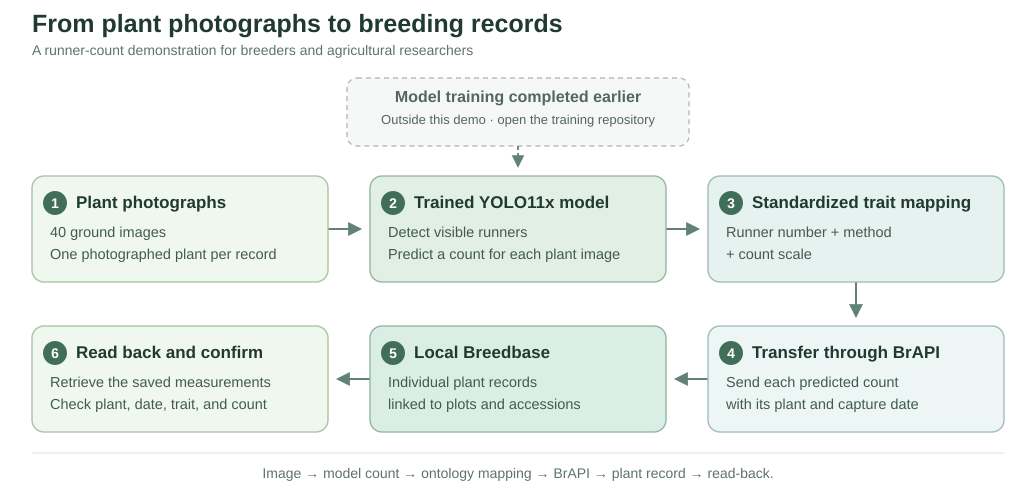

In [2]:
SHOW_PIPELINE_FLOWCHART()

## 1. Meet the plants

For this demonstration, 40 ground images (GI) were selected from the research dataset of
[Zhou et al. (2025)](https://doi.org/10.1016/j.atech.2025.101290), downloaded from
[Dryad](https://doi.org/10.5061/dryad.bzkh189nw). The plants were grown at the strawberry farm
at the University of Florida Gulf Coast Research and Education Center (UF GCREC),
Wimauma, Florida, as part of strawberry breeding trials.

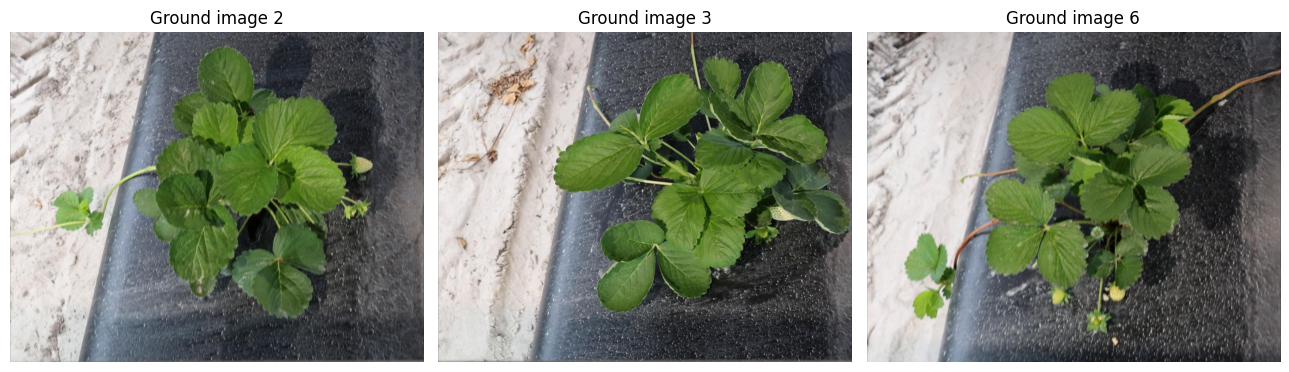

In [3]:
SHOW_STRAWBERRY_IMAGES()

## 2. Count strawberry runners

The trained YOLO11x segmentation model detects runner instances visible in each image.
Each detection contributes one to the predicted count. The three examples below use the
selected photographs; all 40 images remain in the pipeline. No manual count review is required.

The displayed run is identified as saved or newly computed. A completed prediction with no
detections is zero; a failed or missing prediction stops the flow.

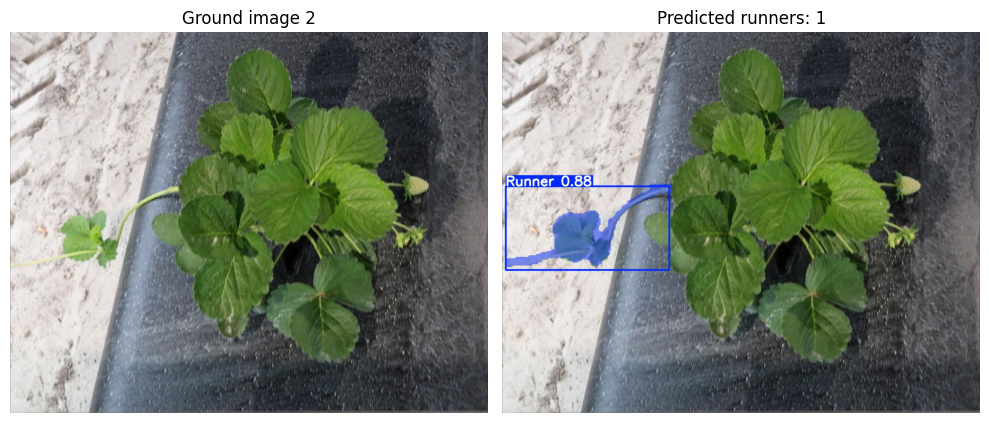

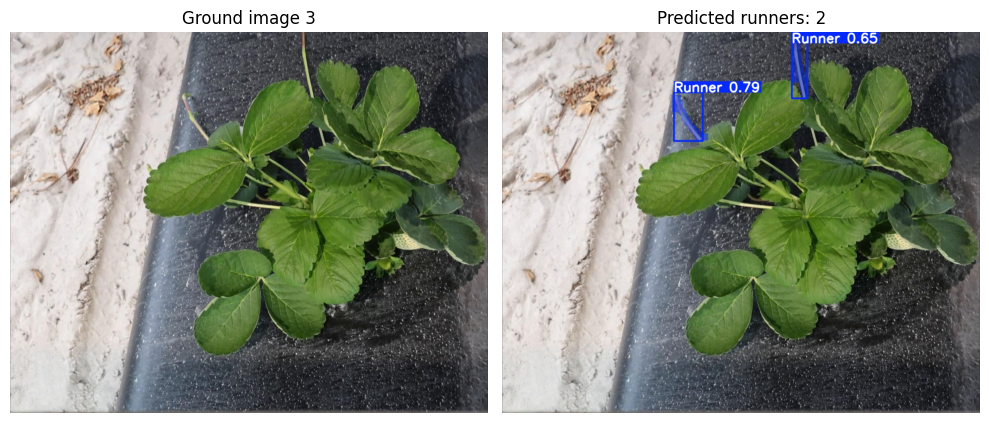

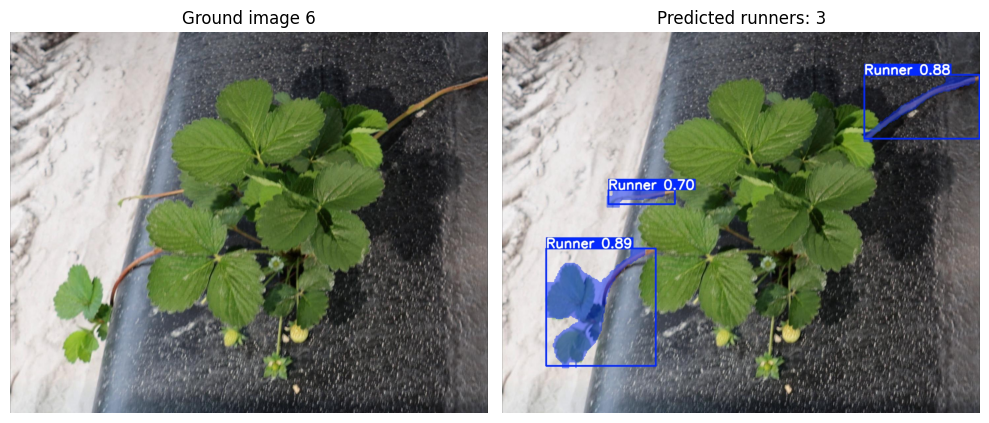

Image,Predicted runners
1,3
2,1
3,2
4,5
5,2
6,3
7,3
8,3
9,1
10,2


In [4]:
COUNT_STRAWBERRY_RUNNER()

## 3. Map the counts to standardized terms

The pipeline automatically applies a predefined mapping: **what** was measured (runner number),
**how** it was measured (the image-analysis method), and **which scale** was used (count).
The strawberry trait and count scale come from Crop Ontology; the YOLO method and combined
observation variable are local definitions. This is an agreed mapping, not ontology discovery by the model.

In [5]:
MAP_RUNNER_COUNTS_TO_ONTOLOGY()

Component,Meaning,Identifier
Trait,Runner number,CO_372:0000104
Method,YOLO11x GI runner counting v1 (local),RUNNERDEMO_METHOD:0000001
Scale,count,CO_372:0000086
Breedbase variable,RUNNERNUM_YOLO11x_GI_count_v1 (local),79806


## 4. Send each measurement to its plant record

BrAPI transfers the model-predicted count to the corresponding individual plant in the local
Breedbase database, together with its image and capture-date provenance. The photograph itself
stays local. Exact existing records are skipped; conflicting records stop the transfer.

**Live upload is enabled.** The table shows the measurements sent to local Breedbase.

In [6]:
UPLOAD_RUNNER_COUNTS_TO_BREEDBASE()

Image,Breedbase plant ID,Photographed,Count to send
1,41863,2023-11-28,3
2,41864,2023-11-28,1
3,41865,2023-11-28,2
4,41866,2023-11-28,5
5,41867,2023-11-28,2
6,41868,2023-11-28,3
7,41869,2023-11-28,3
8,41870,2023-11-28,3
9,41871,2023-11-28,1
10,41872,2023-11-28,2


## 5. Confirm the stored results

After a live upload, the pipeline retrieves the records and verifies the plant, count, measurement
definition, and provenance. A prepared table alone is not proof that data reached the database.

In [7]:
VERIFY_STORED_RUNNER_COUNTS()

## Reproduce or extend the demonstration

The displayed outputs document the completed live run of **30 September 2026**. The dataset photographs and saved prediction-run files are not included; rerunning the model produces a new run.

1. **Get the photographs from Dryad.** Download **GI.zip** from the [Zhou et al. dataset](https://doi.org/10.5061/dryad.bzkh189nw). In its ground-image validation folder (`GI/val/images`, depending on the extraction wrapper), select the 40 filenames listed in [data/image_manifest.csv](data/image_manifest.csv). Create `demo40/images` beside this notebook and copy those files there without renaming or resizing. The helper checks their SHA-256 hashes.
2. **Get the trained model.** Download [strawberry-runner-yolo11x.pt](https://github.com/Bidhan-ghimire/plant-images-to-breeding-records/releases/download/v1.0.0/strawberry-runner-yolo11x.pt) from the [v1.0.0 release](https://github.com/Bidhan-ghimire/plant-images-to-breeding-records/releases/tag/v1.0.0). Create `models` and save the download as `models/best.pt`, or set `STRAWBERRY_RUNNER_CHECKPOINT` to its path. [MODEL_CARD.md](MODEL_CARD.md) gives the verified hash, settings, and limitations.
3. **Prepare the environment.** Use Python 3.10.19 and install [requirements-inference.txt](requirements-inference.txt), which includes [requirements.txt](requirements.txt). The verified inference path requires a compatible NVIDIA GPU and CUDA 12.8. It stops if the checkpoint or required package versions differ.
4. **Run the notebook in order.** The three setup options remain `True` for new inference, upload, and retrieval. To run image counting and ontology mapping without a database, keep `run_predictions=True` and set `upload=False, retrieve=False`. New predictions are written locally and excluded from Git.
5. **Connect your local Breedbase for upload and retrieval.** Provide `BREEDBASE_BRAPI_TOKEN` through the kernel environment, never in notebook source or output. The service address is configured in the helper. Study 170, variable 79806, and the supplied plant IDs belong to the demonstrated database. A different database needs its own matching trial, plants, measurement definition, mapping, and corresponding helper configuration; this repository does not provision or distribute the database. Conflicting existing measurements stop upload.

The short notebook calls load [runner_demo_functions.py](runner_demo_functions.py). The editable diagram is [runner_to_breedbase_flow.drawio](runner_to_breedbase_flow.drawio). See [DATA_SOURCES.md](DATA_SOURCES.md) for image attribution and the capture-date discrepancy.

**If you use the trained model, please cite Zhou et al. (2025) and the Dryad dataset listed below.** These weights were trained in the linked reproduction project; they are not presented as the authors' original checkpoint. The original demonstration code is available under the [MIT License](LICENSE); weights and Ultralytics retain their [upstream terms](THIRD_PARTY_NOTICES.md).

This ground-image demonstration covers runners only. The images were used during model validation, so the demonstration does not establish accuracy on unseen plants. Other traits and imaging workflows require their own models and measurement definitions.


## References

Zhou, X., Wang, X., Ji, L., Daggubati, S., Shen, K., & Whitaker, V. M. (2025).
*Deep learning for strawberry runner detection integrating ground and aerial imaging*.
Smart Agricultural Technology, 12, 101290.
[https://doi.org/10.1016/j.atech.2025.101290](https://doi.org/10.1016/j.atech.2025.101290).

Zhou, X., Wang, X., Whitaker, V., Ji, L., Shen, K., & Daggubati, S. (2025).
*Ground and aerial imagery dataset for strawberry breeding trials: Training deep learning
models for runner detection and segmentation* [Dataset]. Dryad.
[https://doi.org/10.5061/dryad.bzkh189nw](https://doi.org/10.5061/dryad.bzkh189nw).